<table>
    <tr>
        <td style="text-align:left">
            <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" alt="Logo Universidad" width="300"/>
        </td>
        <td>
            Departamento de Ciencias de la Computación y de la Decisión<br>
            Facultad de Minas<br>
            Universidad Nacional de Colombia<br>
            Optimizacion e IA 2026-2S<br><br>
            Docente: Maria Constanza Torres Madronero<br>
            <br>
            Contribuciones a la guia por: <br>
            - Deimer Miranda Montoya (2023)<br>
            - Luis Fernando Becerra Monsalve (2024)
        </td>    
    </tr>
</table>

# **Clasificación usando el perceptron multicapa**




In [1]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Fashion Mnist
Este conjunto de datos contiene 60 000 imágenes en escala de grises de 28x28 píxeles, pertenecientes a 10 categorías de moda, junto con un conjunto de prueba de 10 000 imágenes.

*   x_train: uint8 - Matriz NumPy de datos de imágenes en escala de grises con formas (60000, 28, 28), que contiene los datos de entrenamiento.
*   y_train: uint8 - Matriz NumPy de etiquetas (enteros en el rango 0-9) con forma (60000,)para los datos de entrenamiento.
*   x_test: uint8 - Matriz NumPy de datos de imagen en escala de grises con dimensiones (10000, 28, 28), que contiene los datos de prueba.
*   y_test: uint8 -Matriz NumPy de etiquetas (enteros en el rango 0-9) con forma (10000,)para los datos de prueba.

en 8 bits el número más grande es 255

In [ ]:
#Carga de datos Fashion Mnist
######################################
fasion_mnist = keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fasion_mnist.load_data() # ya estan divididos en entrenamiento y prueba

#Normalizacion de datos
x_valid, x_train = x_train[:5000] / 255,x_train[5000:] / 255
y_valid, y_train = y_train[:5000], y_train[5000:]
x_test = x_test / 255
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


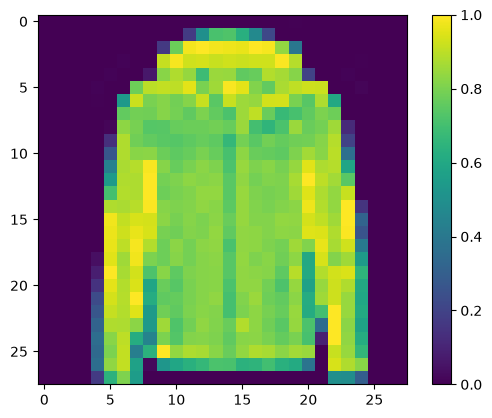

In [ ]:
#Visualizacion de una muestra, está en escala de grises a pesar del color que muestra python 
plt.figure()
plt.imshow(x_train[0])
plt.colorbar()
plt.grid(False)
plt.show()

que cada pixel sea una característica

In [4]:
#Construccion del MLP
model = keras.models.Sequential([
    #Capa flatten: convierte una imagen a un arreglo de caracteristicas: imagen de referencia 28x28 -> arreglo de 784 caracteristicas
    keras.layers.Flatten(input_shape=[28, 28]),
    #Capas oculatas
    keras.layers.Dense(300, activation="relu"), # --> relu para regresion
    keras.layers.Dense(100, activation="relu"),
    #Capa de salida - en clasificación multiclase se recomienda el uso de softmax: probabilidad de 0 a 1 de pertenecer a una clase
    #softmax estima la probabilidad de pertenecer a una de las 10 clases
    keras.layers.Dense(10, activation="softmax") # son una neurona por cada clase a la que quiero que pertenezca
])

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



<img src="https://miro.medium.com/v2/resize:fit:1400/1*Xow3bgENiGDgVG5w4coMYg.png" alt="softmax y relu" width="500"/>



pesos se inicializan aleatorio y bias en 0

In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

la función de pérdida debe ser adaptada a las funciones de probabilidad: 
cross entropy para clasificación 

In [6]:
#Optimizador
optim = keras.optimizers.SGD(learning_rate=3e-3)
#Compilacion
model.compile(  loss = 'sparse_categorical_crossentropy',
                optimizer = optim,
                metrics = ['accuracy'] #ir monitorendo el accuracy durante el entrenamiento y la evaluacion
              )
#Entrenamiento
history = model.fit(x_train, y_train, epochs=15,
                    validation_data=(x_valid, y_valid))
#Evaluacion
model.evaluate(x_test, y_test)

Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.6995 - loss: 0.9978 - val_accuracy: 0.7858 - val_loss: 0.6580
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7999 - loss: 0.6080 - val_accuracy: 0.8254 - val_loss: 0.5424
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8220 - loss: 0.5332 - val_accuracy: 0.8376 - val_loss: 0.4940
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8314 - loss: 0.4960 - val_accuracy: 0.8478 - val_loss: 0.4668
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8389 - loss: 0.4724 - val_accuracy: 0.8544 - val_loss: 0.4489
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8441 - loss: 0.4553 - val_accuracy: 0.8586 - val_loss: 0.4357
Epoch 7/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8481 - loss: 0.4420 - val_accuracy: 0.8608 - val_loss: 0.4254
Epoch 8/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8514 - loss: 0.4310 -

[0.4174391031265259, 0.8518999814987183]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


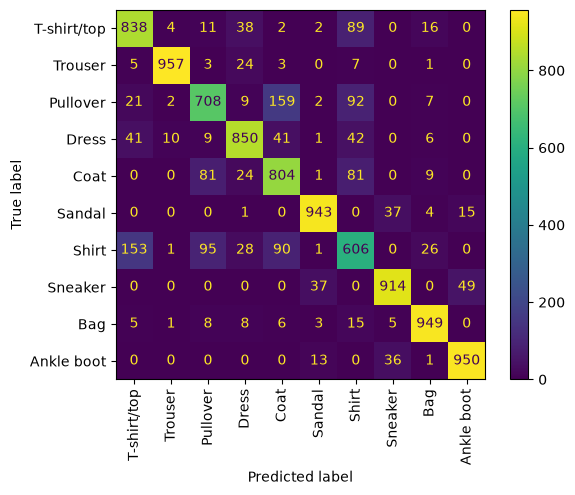

In [14]:
#Predicción: corresponde a la probabilidad de pertenecer a cada clase
y_pred_prob = model.predict(x_test)
# Convertir probabilidades a clases
y_pred = np.argmax(y_pred_prob, axis=1)
#Calculo de la matriz de confusión
cm_rf = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=class_names)
disp.plot( xticks_rotation=90)

# Selección de hiperparametros

Para la selección de los hiperparametros de una red neuronal (MLP o DL) existen varias librerías. En esta práctica usares Keras Tuner. Dado que esta área aun esta en desarrollo, estas librerías se encuentran en constante desarrollo y actualización.   


In [ ]:
#pip install keras-tuner --upgrade

In [17]:
#Importar la libreria
import keras_tuner as kt

In [ ]:
#Definicion del modelo
def model_builder(hp):
  #USamos el modelo sequencial
  model = keras.Sequential()
  #Agregamos la capa para organizar los datos
  model.add(keras.layers.Flatten(input_shape=(28,28)))
  #Vamos a seleccionar el numero de neuronas de una capa oculta
  #Vamos a elegir entre 32 a 512 neuronas
  hp_units = hp.Int('units', min_value=32, max_value=512, step=32) # hacer un arreglo de valores para ver el mejor --> mejor cantidad de neuronas
  model.add(keras.layers.Dense(units=hp_units, activation='relu'))
  #Agregamos la capa de salida
  model.add(keras.layers.Dense(10,activation="softmax"))
  #Adicionalmente vamos a seleccionar el paso de aprendizaje
  #Vamos a comparar los valores 0.01, 0.001, 0.0001
  hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
  #Incluimos la compilacion del modelo
  model.compile(optimizer=keras.optimizers.SGD(learning_rate=hp_learning_rate),
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
  return model

In [ ]:
#Ahora vamos a aplica busqueda aleatoria, buscando mejorar la precision
#de validacion
tuner = kt.RandomSearch(
    hypermodel=model_builder,
    objective= 'val_accuracy',
    max_trials = 3, #numero de pruebas --> defecto 10 la idea es incrementar el numero de pruebas para mejorar la precision
    directory = 'random_hyperparameter_tuning',
    project_name='mnist_classification'
    )
#El numero de pruebas por defecto es 10, vamos a limitarlo a 3 dado
#el tiempo de computo

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [19]:
#Keras-tuner tiene diferentes funcionalidades, por ejemplo guardar cada
#modelo, o el mejor modelo en cada prueba. Una funcionalidad interesante
#es parar una prueba si el desempeno no esta mejorando, para esto usamos

# variable del monitoreo en el conjunto de validacion 
# paciencia: si no mejora me detengo 
stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3) 

#ahora, realizamos la busqueda, por el tiempo de computo vamos a limitar
#el numero de epocas a 15
tuner.search(x_train, y_train, epochs=15,
             validation_data=(x_valid,y_valid),
             callbacks=[stop_early])


Trial 3 Complete [00h 01m 26s]
val_accuracy: 0.8677999973297119

Best val_accuracy So Far: 0.8758000135421753
Total elapsed time: 00h 04m 57s


In [20]:
#Mostremos los parametros seleccionados
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("El numero de neuronas en la capa oculta seleccionado es: ", best_hps.get('units'),
      "y el paso de aprendizaje: ", best_hps.get('learning_rate'))

El numero de neuronas en la capa oculta seleccionado es:  128 y el paso de aprendizaje:  0.01


In [21]:
#Obtengamos el modelo entrenado
best_model = tuner.get_best_models(num_models=1)[0]
best_model.summary()

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
#Evaluacion del modelo
best_model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8632 - loss: 0.3890


[0.3890475928783417, 0.8632000088691711]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


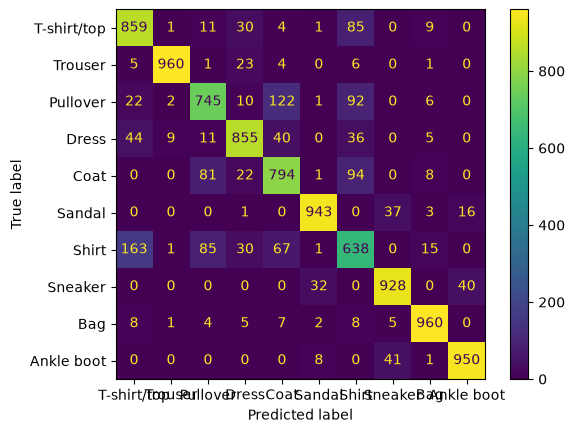

In [23]:
#Prediccion
y_pred_prob = best_model.predict(x_test)
# Convertir probabilidades a clases
y_pred = np.argmax(y_pred_prob, axis=1)
#Calculo de la matriz de confusion
cm_rf = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=class_names)
disp.plot()

## bayesiano

In [24]:
#Ahora vamos a aplicar optimización bayesiana, buscando mejorar la precision
#de validacion

# el bayesiano hace unos experimentos iniciales y luego va ajustando el modelo para mejorar la precision de validacion
# por eso solo correrlo 3 veces es muy poco 
tuner = kt.BayesianOptimization(
    hypermodel=model_builder,
    objective='val_accuracy',
    max_trials=10,
    num_initial_points=3,
    directory='random_hyperparameter_tuning',
    project_name='bayesian_mnist_classification'
)



c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [25]:
#Keras-tuner tiene diferentes funcionalidades, por ejemplo guardar cada
#modelo, o el mejor modelo en cada prueba. Una funcionalidad interesante
#es parar una prueba si el desempeno no esta mejorando, para esto usamos
stop_early = keras.callbacks.EarlyStopping(monitor='val_accuracy',patience=3)
#ahora, realizamos la busqueda, por el tiempo de computo vamos a limitar
#el numero de epocas a 15
tuner.search(x_train, y_train, epochs=15,
             validation_data=(x_valid,y_valid),
             callbacks=[stop_early])

Trial 10 Complete [00h 02m 29s]
val_accuracy: 0.8817999958992004

Best val_accuracy So Far: 0.8826000094413757
Total elapsed time: 00h 19m 16s


In [ ]:
#Mostremos los parametros seleccionados
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("El numero de neuronas en la capa oculta seleccionado es: ", best_hps.get('units'),
      "y el paso de aprendizaje: ", best_hps.get('learning_rate'))

In [ ]:
#Obtengamos el modelo entrenado
best_model = tuner.get_best_models(num_models=1)[0]
best_model.summary()

In [ ]:
#Evaluacion del modelo
best_model.evaluate(x_test, y_test)

In [ ]:
#Prediccion
y_pred_prob = best_model.predict(x_test)
# Convertir probabilidades a clases
y_pred = np.argmax(y_pred_prob, axis=1)
# Calculo de la matriz de confusion
cm_rf = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=class_names)
disp.plot()

Tienes mucha claridad en cómo funciona el panorama general, pero hay un par de precisiones importantes que debemos ajustar en tu lógica para que todo encaje a la perfección. 

1. ¿Quién reduce el error? (Corrección clave)La función de activación no reduce el error por sí misma. Su trabajo es darle "curvas" (no linealidad) al modelo para que pueda entender formas complejas en la imagen (como bordes u ojos). Quien realmente se encarga de reducir el error optimizando los pesos (\[w\]) y el bias (\[b\]) es el Optimizador (usando un algoritmo llamado Gradiente Descendiente y Backpropagation), guiado por una Función de Pérdida (Loss Function). 

2. ¿Cómo se mide el error? (Entrenamiento vs. Validación)El error no se calcula comparando el entrenamiento contra la validación. El proceso funciona en dos etapas separadas: Durante el entrenamiento: El modelo ve las imágenes de entrenamiento, calcula su error comparando su predicción actual contra la etiqueta real de esa misma imagen de entrenamiento, y ajusta los pesos (\[w\]) y bias (\[b\]) inmediatamente para mejorar. Durante la validación: Usas las imágenes de validación (que el modelo nunca ha visto) para evaluar el porcentaje de aciertos (Accuracy). Esto sirve para comprobar si el modelo realmente aprendió a generalizar o si solo memorizó las fotos de entrenamiento (efecto conocido como overfitting). El flujo real en una neurona de clasificación de imágenes:


'''
[Píxeles de la Imagen] 
         │
         ▼
 1. Suma ponderada ───► (Píxeles × w) + b
         │
         ▼
 2. Función de Activación ───► Transforma el resultado (Ej: Softmax da la probabilidad de que sea un "gato")
         │
         ▼
 3. Función de Pérdida ───► Compara esa probabilidad contra la etiqueta real (Ej: "gato" vs "perro")
         │
         ▼
 4. Optimizador ───► Ajusta los pesos (w) y bias (b) para que el error sea menor la próxima vez
'''



## ¿Qué hace realmente la función de activación? 

(La analogía del interruptor)La suma ponderada $((x \cdot w) + b)$ solo te da un número continuo que puede ir desde el infinito negativo hasta el infinito positivo (por ejemplo: -358.4, 0, o 1240.5). La función de activación toma ese número infinito y lo transforma en algo útil. 

Actúa como un filtro o un interruptor inteligente: Decide la intensidad de la señal: Traduce un resultado matemático abstracto en un estado de activación. ¿La neurona debe ignorar esta información (salida cercana a 0)? ¿O es crucial y debe pasar con toda su fuerza (salida cercana a 1 o un valor alto)? Rompe la linealidad (El "superpoder"): 

Si solo multiplicas y sumas, estás haciendo álgebra lineal básica. Sin función de activación, por más capas que le pongas a tu red, el resultado final siempre será una línea recta. En clasificación de imágenes, el mundo real no se divide con líneas rectas; necesitas curvas complejas para separar un gato de un perro. Estas funciones deforman el espacio matemático para permitir curvas. 2. ¿Qué tienen de especial ReLU, Sigmoide y Softmax?No se puede usar cualquier función matemática. Las que usamos tienen propiedades estadísticas y de cálculo (son derivables, lo cual es obligatorio para que el optimizador pueda ajustar los pesos) que resuelven problemas específicos. Aquí tienes el porqué de cada una: 


🧠 **ReLU (Rectified Linear Unit)** —__La reina de las capas ocultas__ ¿Qué hace? Si el número es negativo, lo convierte en 0. Si es positivo, lo deja exactamente igual. ¿Qué tiene de especial?Velocidad extrema: Para la computadora, calcular f(x) = max(0, x) es increíblemente barato y rápido comparado con hacer operaciones matemáticas complejas.Apagado selectivo (Esparcidad): Al volver 0 todos los valores negativos, "apaga" las neuronas que no están aportando. Esto hace que la red sea eficiente y se enfoque solo en las características importantes (como un borde específico de la imagen). 

📈 **Sigmoide** — __El medidor de probabilidad individual__ ¿Qué hace? Toma cualquier número y lo comprime estrictamente en un rango entre 0 y 1.¿Qué tiene de especial? Su curva tiene forma de "S". Al dar un valor entre 0 y 1, su salida se puede interpretar directamente como una probabilidad (ej. 0.85 significa 85% de probabilidad de que la imagen sea un gato). Se usa al final de la red si tu problema es decir "Sí" o "No" (clasificación binaria).

📊 **Softmax** — __La repartidora de porcentajes__ ¿Qué hace? Toma un grupo de números de varias neuronas de salida, los normaliza y hace que todos sumen exactamente 1 (100%).¿Qué tiene de especial? Se usa exclusivamente en la última capa cuando tienes múltiples categorías (ej. clasificar si la imagen es un perro, un gato, o un pájaro). Si la red arroja puntajes independientes para cada animal, Softmax los transforma en una distribución de probabilidad competitiva: [Perro: 70%, Gato: 20%, Pájaro: 10%]. 


En resumen: 

ReLUCapas ocultas (intermedias). Hace que la red sea súper rápida de entrenar y prender/apagar neuronas.

SigmoideCapa de salida (Binaria: Sí/No)Transforma el resultado en una probabilidad única entre 0 y 1.

SoftmaxCapa de salida (Multiclase)Hace que las predicciones de varias opciones compitan y sumen 100%.